In [1]:
# %% [markdown]
# # A diffusion model you can train on a laptop: 8×8 digits
#
# **Folder:** [18 Diffusion and image generation](README.md) · **Runtime:** about 6 minutes on a CPU
#
# This notebook builds a complete, class-conditional diffusion model (DDPM, Ho, Jain & Abbeel 2020) on scikit-learn's
# 8×8 handwritten digits. The denoiser is a small **U-Net**: convolutions, residual blocks, a self-attention layer, and
# time and class embeddings. It is the same design as the networks behind Stable Diffusion, at about 270k parameters
# instead of about 900M.
#
# It is organised around one question:
#
# > *If every image is noised until it becomes pure noise, and generation starts from fresh random noise, how does the
# > model know which image you want?*
#
# The short answer, which sections 6–9 demonstrate:
#
# 1. **It doesn't recover a particular training image, and isn't meant to.** The forward process destroys all
#    information about the starting image. A diffusion model learns the *distribution* of images, and sampling draws a
#    **new** image from it. The starting noise is a random seed: different noise gives a different, new digit.
# 2. **You say what you want with conditioning.** The label (a class here; a text embedding in Stable Diffusion) is an
#    input to the network **at every denoising step**. The noise decides the *style*; the condition decides the
#    *content*. Classifier-free guidance makes the model follow the condition more strictly.
# 3. **The noise is a code.** With a deterministic sampler (DDIM), the same noise always gives the same image, and
#    nearby noises give similar images.
# 4. **If you want a *specific* image** (a variation of one you have), don't start from pure noise: noise the image
#    part-way and denoise it from there (SDEdit). How far you noise it sets how much of the original survives.

In [2]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

plt.rcParams.update({"figure.dpi": 110, "image.cmap": "gray_r"})


def show_grid(imgs, rows, cols, title=None, row_labels=None, size=0.75):
    """imgs: (n, 8, 8) or (n, 8, 8, 1) in [-1, 1]."""
    imgs = np.asarray(imgs).reshape(-1, 8, 8)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size))
    for i, ax in enumerate(np.atleast_1d(axes).flat):
        ax.imshow(imgs[i], vmin=-1, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if row_labels is not None and i % cols == 0:
            ax.set_ylabel(row_labels[i // cols], rotation=0, ha="right", va="center", fontsize=8)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()

## 1. The data

1797 grayscale digits, 8×8 pixels, rescaled from [0, 16] to [−1, 1]. Images in [−1, 1] are the usual convention,
so that "pure noise" N(0, 1) and the data are on the same scale.

(1797, 8, 8, 1) pixel range -1.0 1.0


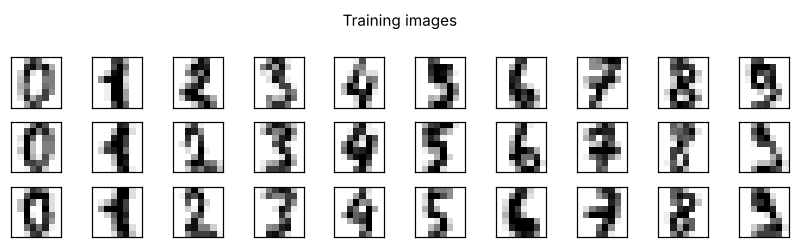

In [3]:
digits = load_digits()
X = (digits.images / 16.0 * 2 - 1).astype(np.float32)[..., None]   # (1797, 8, 8, 1), NHWC
Y = digits.target.astype(np.int32)
print(X.shape, "pixel range", X.min(), X.max())
show_grid(X[:30], 3, 10, "Training images")

## 2. The forward process: turning images into noise

We never learn this part; it is fixed. At step $t$ the image is

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon, \qquad \varepsilon \sim \mathcal N(0, I),$$

where $\bar\alpha_t$ falls from 1 to 0. We use $T = 200$ steps and the **cosine schedule** (Nichol & Dhariwal 2021),
which removes the signal more evenly than DDPM's linear schedule. The quantity that matters is the
signal-to-noise ratio $\bar\alpha_t / (1-\bar\alpha_t)$.

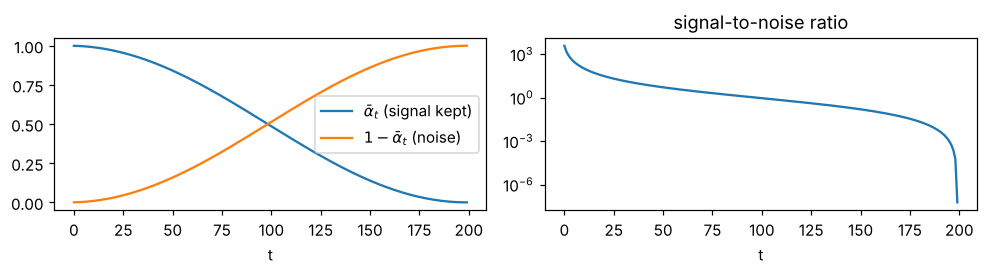

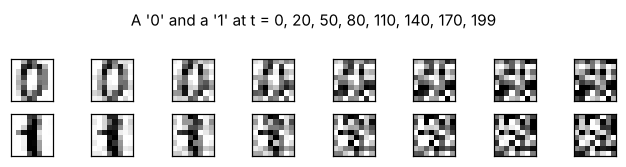

In [4]:
T = 200
s = 0.008
f = np.cos((np.arange(T + 1) / T + s) / (1 + s) * np.pi / 2) ** 2
BETAS = np.clip(1 - f[1:] / f[:-1], 0, 0.999)           # beta_t, clipped so the last step is not exactly 1
ALPHAS = (1 - BETAS).astype(np.float32)
BETAS = BETAS.astype(np.float32)
ABAR = np.cumprod(ALPHAS).astype(np.float64)             # abar_t for t = 0..T-1 (tiny but > 0 at t = T-1)
ABAR_PREV = np.r_[1.0, ABAR[:-1]]
SIGMA = np.sqrt(BETAS * (1 - ABAR_PREV) / (1 - ABAR))    # std of the reverse step (posterior variance)


def q_sample(x0, t, eps):
    return (np.sqrt(ABAR[t]) * x0 + np.sqrt(1 - ABAR[t]) * eps).astype(np.float32)


fig, ax = plt.subplots(1, 2, figsize=(9, 2.6))
ax[0].plot(ABAR, label=r"$\bar\alpha_t$ (signal kept)")
ax[0].plot(1 - ABAR, label=r"$1-\bar\alpha_t$ (noise)")
ax[0].set_xlabel("t"); ax[0].legend()
ax[1].semilogy(ABAR / (1 - ABAR)); ax[1].set_xlabel("t"); ax[1].set_title("signal-to-noise ratio")
plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
ts = [0, 20, 50, 80, 110, 140, 170, 199]
two = X[[0, 1]]                       # a "0" and a "1"
eps = rng.standard_normal(two.shape).astype(np.float32)
row = [q_sample(two[i], t, eps[i]) for i in range(2) for t in ts]
show_grid(row, 2, len(ts), "A '0' and a '1' at t = " + ", ".join(map(str, ts)))

By $t = 199$ the "0" and the "1" are indistinguishable. Here is how much of the original image is left, measured as
the correlation between $x_t$ and $x_0$ over the whole dataset:

In [5]:
eps_all = rng.standard_normal(X.shape).astype(np.float32)
for t in [0, 50, 100, 150, 199]:
    xt = q_sample(X, t, eps_all)
    c = np.corrcoef(xt.ravel(), X.ravel())[0, 1]
    print(f"t = {t:3d}: sqrt(abar) = {np.sqrt(ABAR[t]):.3f}, correlation(x_t, x_0) = {c:.3f}")

t =   0: sqrt(abar) = 1.000, correlation(x_t, x_0) = 1.000
t =  50: sqrt(abar) = 0.917, correlation(x_t, x_0) = 0.866
t = 100: sqrt(abar) = 0.697, correlation(x_t, x_0) = 0.590
t = 150: sqrt(abar) = 0.373, correlation(x_t, x_0) = 0.289
t = 199: sqrt(abar) = 0.000, correlation(x_t, x_0) = -0.000


At $t = T-1$ essentially nothing of the image is left. **This is the key to the question at the top.** The model
could not recover "your" image from $x_T$ even in principle, because the information is gone. So the reverse process
is not "undo the noise for this image". It is "turn noise into *some* image that looks like it came from the data".
The randomness of $x_T$ picks which one.

## 3. What the network learns

The network $\varepsilon_\theta(x_t, t, y)$ sees a noisy image, the step $t$ and (optionally) a label $y$, and
predicts the noise $\varepsilon$ that was added. Training is plain regression (DDPM's simplified loss):

$$\mathcal L = \mathbb E_{x_0, y, t, \varepsilon}\,\big\|\varepsilon - \varepsilon_\theta\big(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\varepsilon,\ t,\ y\big)\big\|^2 .$$

Predicting $\varepsilon$ is the same as predicting the clean image, since
$\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$. It is also the same as estimating
the score $\nabla_x \log p_t(x_t) = -\hat\varepsilon/\sqrt{1-\bar\alpha_t}$, the direction toward more probable images.

With probability 15% we replace the label by a special **"null" label** (index 10). One network then learns both
$\varepsilon_\theta(x_t, t, y)$ and the unconditional $\varepsilon_\theta(x_t, t, \varnothing)$, which is what
classifier-free guidance needs (section 8).

## 4. The network: a small U-Net

```
                 t ──► sinusoidal(32) ──► Dense 64 ──► SiLU ──► Dense 64 ──┐
                                                                           (+)──► embedding e (64)
                 y ──► lookup table: 11 labels (0–9 and "null") × 64 ───────┘        │ (into every ResBlock)

 x_t  8×8×1 ──► Conv3×3 ──► 8×8×32 ──► ResBlock(32→32, e) ──► h1  8×8×32 ─────────────────┐ skip connection
                                                              │                            │
                                              Conv3×3 stride 2 (downsample)                │
                                                              ▼                            │
                                                   4×4×64 ──► ResBlock(64→64, e)           │
                                                          ──► Self-attention over 16 positions
                                                          ──► ResBlock(64→64, e)           │
                                                              │                            │
                                      nearest-neighbour upsample ×2, Conv3×3 → 8×8×32      │
                                                              ▼                            │
                                     concatenate with h1 ──► 8×8×64 ◄──────────────────────┘
                                                          ──► ResBlock(64→32, e)
                                                          ──► GroupNorm, SiLU, Conv3×3 ──► ε̂  8×8×1
```

What each piece is for:

| Part | Why it is there |
| --- | --- |
| **Encoder–decoder (U shape)** | Downsampling lets each unit see the whole 8×8 image (global shape: *which digit*); the full-resolution path handles strokes and edges. |
| **Skip connection** (concatenate `h1`) | Passes fine detail straight to the output, so the bottleneck doesn't have to carry it. This is what makes it a U-Net. |
| **ResBlock** = GroupNorm → SiLU → Conv3×3 → **+ Dense(e)** → GroupNorm → SiLU → Conv3×3, plus the input | The residual form keeps training stable; adding `Dense(e)` as a per-channel bias tells every block the noise level and the label. |
| **Time embedding** | The same network handles every $t$; at high noise it must guess global shape, at low noise it removes faint speckle. Sinusoidal features make nearby $t$ similar. |
| **Class embedding** | The conditioning. It enters **every** ResBlock at **every** step, which is how the label steers the whole trajectory. Stable Diffusion uses a text encoder instead, injected with cross-attention. |
| **Self-attention** at 4×4 | Lets any position read from any other, as in the U-Nets of DDPM and Stable Diffusion. |
| **Zero-initialised last convolutions** | Each ResBlock starts as the identity and the network starts by predicting 0, which keeps early training stable. |

In [6]:
EMB = 64          # width of the time + class embedding
NULL = 10         # the "no label" token used for classifier-free guidance


def dense_init(k, a, b, scale=1.0):
    return dict(W=jax.random.normal(k, (a, b)) * np.sqrt(1 / a) * scale, b=jnp.zeros(b))


def conv_init(k, cin, cout, ks=3, scale=1.0):
    return dict(W=jax.random.normal(k, (ks, ks, cin, cout)) * np.sqrt(1 / (ks * ks * cin)) * scale, b=jnp.zeros(cout))


def dense(p, x):
    return x @ p["W"] + p["b"]


def conv(p, x, stride=1):
    return jax.lax.conv_general_dilated(x, p["W"], (stride, stride), "SAME",
                                        dimension_numbers=("NHWC", "HWIO", "NHWC")) + p["b"]


def group_norm(x, groups=8, eps=1e-5):
    n, h, w, c = x.shape
    g = x.reshape(n, h, w, groups, c // groups)
    g = (g - g.mean((1, 2, 4), keepdims=True)) / jnp.sqrt(g.var((1, 2, 4), keepdims=True) + eps)
    return g.reshape(n, h, w, c)


def resblock_init(k, cin, cout):
    k = jax.random.split(k, 4)
    p = dict(conv1=conv_init(k[0], cin, cout), emb=dense_init(k[1], EMB, cout),
             conv2=conv_init(k[2], cout, cout, scale=0.0))
    if cin != cout:
        p["skip"] = conv_init(k[3], cin, cout, ks=1)       # 1×1 conv to match channels
    return p


def resblock(p, x, e):
    h = conv(p["conv1"], jax.nn.silu(group_norm(x)))
    h = h + dense(p["emb"], e)[:, None, None, :]           # inject time + class
    h = conv(p["conv2"], jax.nn.silu(group_norm(h)))
    return (conv(p["skip"], x) if "skip" in p else x) + h


def attention_init(k, c):
    k = jax.random.split(k, 2)
    return dict(qkv=dense_init(k[0], c, 3 * c), out=dense_init(k[1], c, c, scale=0.0))


def attention(p, x):
    n, h, w, c = x.shape
    z = group_norm(x).reshape(n, h * w, c)                 # 16 "tokens" of 64 channels
    q, k, v = jnp.split(dense(p["qkv"], z), 3, -1)
    a = jax.nn.softmax(q @ k.transpose(0, 2, 1) / np.sqrt(c), -1)
    return x + dense(p["out"], a @ v).reshape(n, h, w, c)


def sinusoidal(t, dim=32):
    freqs = np.exp(-np.log(1000) * np.arange(dim // 2) / (dim // 2))
    a = t[:, None] * freqs[None]
    return jnp.concatenate([jnp.sin(a), jnp.cos(a)], -1)


def init(key):
    k = jax.random.split(key, 12)
    return dict(
        time1=dense_init(k[0], 32, EMB), time2=dense_init(k[1], EMB, EMB),
        class_table=jax.random.normal(k[2], (11, EMB)) * 0.5,
        conv_in=conv_init(k[3], 1, 32),
        res1=resblock_init(k[4], 32, 32),
        down=conv_init(k[5], 32, 64),
        res2=resblock_init(k[6], 64, 64),
        attn=attention_init(k[7], 64),
        res3=resblock_init(k[8], 64, 64),
        up=conv_init(k[9], 64, 32),
        res4=resblock_init(k[10], 64, 32),
        conv_out=conv_init(k[11], 32, 1, scale=0.0),
    )


def unet(p, x, t, y, trace=None):
    """eps_theta(x_t, t, y). x: (n, 8, 8, 1), t: (n,) ints, y: (n,) labels in 0..10 (10 = null)."""
    log = (lambda name, v: trace.append((name, v.shape))) if trace is not None else (lambda *_: None)
    e = dense(p["time2"], jax.nn.silu(dense(p["time1"], sinusoidal(t)))) + p["class_table"][y]
    log("embedding e", e)
    h = conv(p["conv_in"], x);                   log("conv_in", h)
    h1 = resblock(p["res1"], h, e);              log("res1 (kept for the skip)", h1)
    h = conv(p["down"], h1, stride=2);           log("downsample", h)
    h = resblock(p["res2"], h, e);               log("res2", h)
    h = attention(p["attn"], h);                 log("self-attention", h)
    h = resblock(p["res3"], h, e);               log("res3", h)
    h = jnp.repeat(jnp.repeat(h, 2, 1), 2, 2)
    h = conv(p["up"], h);                        log("upsample + conv", h)
    h = jnp.concatenate([h, h1], -1);            log("concat skip", h)
    h = resblock(p["res4"], h, e);               log("res4", h)
    out = conv(p["conv_out"], jax.nn.silu(group_norm(h))); log("conv_out = predicted noise", out)
    return out


params = init(jax.random.PRNGKey(0))
trace = []
unet(params, jnp.zeros((5, 8, 8, 1)), jnp.zeros(5, int), jnp.zeros(5, int), trace)
print("Shapes for a batch of 5:")
for name, shape in trace:
    print(f"  {name:28s} {shape}")
print("\nParameters per block:")
for name, sub in params.items():
    print(f"  {name:12s} {sum(v.size for v in jax.tree_util.tree_leaves(sub)):7,d}")
print(f"  {'total':12s} {sum(v.size for v in jax.tree_util.tree_leaves(params)):7,d}")

Shapes for a batch of 5:
  embedding e                  (5, 64)
  conv_in                      (5, 8, 8, 32)
  res1 (kept for the skip)     (5, 8, 8, 32)
  downsample                   (5, 4, 4, 64)
  res2                         (5, 4, 4, 64)
  self-attention               (5, 4, 4, 64)
  res3                         (5, 4, 4, 64)
  upsample + conv              (5, 8, 8, 32)
  concat skip                  (5, 8, 8, 64)
  res4                         (5, 8, 8, 32)
  conv_out = predicted noise   (5, 8, 8, 1)

Parameters per block:
  time1          2,112
  time2          4,160
  class_table      704
  conv_in          320
  res1          20,576
  down          18,496
  res2          78,016
  attn          16,640
  res3          78,016
  up            18,464
  res4          31,872
  conv_out         289
  total        269,665


## 5. Training

Each step: draw a batch of images and labels, a random step $t$ for each image, and fresh noise $\varepsilon$; make
$x_t$; drop 15% of labels to "null"; regress the network's output onto $\varepsilon$. Adam with warm-up and cosine
decay, 4000 steps of 128 images (about 4 minutes on a laptop CPU).

step     0  loss 0.9995  (2 s)


step  1000  loss 0.1405  (57 s)


step  2000  loss 0.1284  (115 s)


step  3000  loss 0.1202  (172 s)


step  3999  loss 0.1173  (228 s)


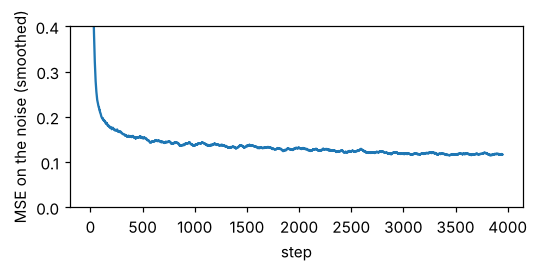

In [7]:
STEPS, BATCH, P_UNCOND = 4000, 128, 0.15
opt = optax.adam(optax.warmup_cosine_decay_schedule(0.0, 2e-3, 200, STEPS))
opt_state = opt.init(params)
sqrt_abar, sqrt_1m_abar = jnp.asarray(np.sqrt(ABAR), jnp.float32), jnp.asarray(np.sqrt(1 - ABAR), jnp.float32)


def loss_fn(p, x0, y, key):
    k1, k2, k3 = jax.random.split(key, 3)
    t = jax.random.randint(k1, (len(x0),), 0, T)
    eps = jax.random.normal(k2, x0.shape)
    xt = sqrt_abar[t][:, None, None, None] * x0 + sqrt_1m_abar[t][:, None, None, None] * eps
    y = jnp.where(jax.random.uniform(k3, y.shape) < P_UNCOND, NULL, y)
    return jnp.mean((unet(p, xt, t, y) - eps) ** 2)


@jax.jit
def train_step(p, state, x0, y, key):
    loss, g = jax.value_and_grad(loss_fn)(p, x0, y, key)
    updates, state = opt.update(g, state)
    return optax.apply_updates(p, updates), state, loss


rng = np.random.default_rng(0)
key = jax.random.PRNGKey(1)
losses, t0 = [], time.time()
for i in range(STEPS):
    idx = rng.integers(0, len(X), BATCH)
    key, sub = jax.random.split(key)
    params, opt_state, loss = train_step(params, opt_state, X[idx], Y[idx], sub)
    losses.append(float(loss))
    if i % 1000 == 0 or i == STEPS - 1:
        print(f"step {i:5d}  loss {np.mean(losses[-200:]):.4f}  ({time.time() - t0:.0f} s)")

plt.figure(figsize=(5, 2.5))
plt.plot(np.convolve(losses, np.ones(50) / 50, "valid"))
plt.xlabel("step"); plt.ylabel("MSE on the noise (smoothed)"); plt.ylim(0, 0.4)
plt.tight_layout(); plt.show()

The loss can't reach 0: at large $t$ the noise is almost all of $x_t$ and easy to predict, but at small $t$ the
network would have to guess which tiny bit of $x_t$ is noise and which is digit.

## 6. Generating: start from noise, denoise step by step

**Ancestral (DDPM) sampling.** Start from $x_T \sim \mathcal N(0, I)$, and for $t = T-1, \dots, 0$:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\hat\varepsilon\Big) + \sigma_t z, \qquad z\sim\mathcal N(0, I).$$

**DDIM sampling** (Song, Meng & Ermon 2021) uses the *same trained network* but no fresh noise: it predicts
$\hat x_0$, then moves deterministically to the next noise level. It can skip steps (here 50 instead of 200), and the
result is a deterministic function of $x_T$.

**Classifier-free guidance** with weight $w$ replaces $\hat\varepsilon$ by
$(1+w)\,\varepsilon_\theta(x_t,t,y) - w\,\varepsilon_\theta(x_t,t,\varnothing)$, which pushes the sample further in
the direction that makes it look like class $y$.

In [8]:
eps_net = jax.jit(unet)


def guided_eps(x, t, y, w):
    n = x.shape[0]
    tt = jnp.full(n, t)
    e = eps_net(params, x, tt, y)
    if w != 0:
        e = (1 + w) * e - w * eps_net(params, x, tt, jnp.full(n, NULL))
    return e


def sample_ddpm(xT, y, w=0.0, seed=0, keep=()):
    """Ancestral sampling. xT: (n, 8, 8, 1). y: labels (NULL = unconditional). keep: steps at which to record x̂_0."""
    key = jax.random.PRNGKey(seed)
    x, y, snaps = jnp.asarray(xT), jnp.asarray(y), {}
    for t in range(T - 1, -1, -1):
        e = guided_eps(x, t, y, w)
        if t in keep:
            snaps[t] = (np.asarray(x), np.asarray((x - np.sqrt(1 - ABAR[t]) * e) / np.sqrt(ABAR[t])))
        x = (x - BETAS[t] / np.sqrt(1 - ABAR[t]) * e) / np.sqrt(ALPHAS[t])
        if t > 0:
            key, sub = jax.random.split(key)
            x = x + SIGMA[t] * jax.random.normal(sub, x.shape)
    return np.clip(np.asarray(x), -1, 1), snaps


def sample_ddim(xT, y, w=0.0, n_steps=50, t_start=T - 1):
    """Deterministic DDIM sampling from step t_start down to 0, on an evenly spaced subset of steps."""
    steps = np.linspace(t_start, 0, n_steps).round().astype(int)
    x, y = jnp.asarray(xT), jnp.asarray(y)
    for i, t in enumerate(steps):
        e = guided_eps(x, int(t), y, w)
        x0 = jnp.clip((x - np.sqrt(1 - ABAR[t]) * e) / np.sqrt(ABAR[t]), -1, 1)
        e = (x - np.sqrt(ABAR[t]) * x0) / np.sqrt(1 - ABAR[t])   # keep the noise estimate consistent with the clip
        if i + 1 < len(steps):
            tn = steps[i + 1]
            x = np.sqrt(ABAR[tn]) * x0 + np.sqrt(1 - ABAR[tn]) * e
        else:
            x = x0
    return np.asarray(x)


def noise(n, seed):
    return np.random.default_rng(seed).standard_normal((n, 8, 8, 1)).astype(np.float32)


# A "judge": logistic regression trained on the real digits, used to read off which digit a sample is.
judge = LogisticRegression(max_iter=5000).fit(X.reshape(len(X), -1), Y)
classify = lambda S: judge.predict(np.asarray(S).reshape(len(S), -1))
print(f"judge accuracy on its own training images: {np.mean(classify(X) == Y):.3f}")

judge accuracy on its own training images: 0.996


### Watching one sample form

Top row: the current noisy image $x_t$. Bottom row: the network's guess of the final image, $\hat x_0$, at that
step. Here the label is "3".

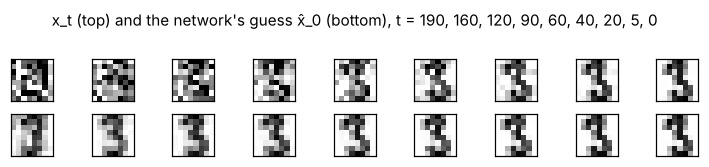

In [9]:
keep = [190, 160, 120, 90, 60, 40, 20, 5, 0]
_, snaps = sample_ddpm(noise(1, 7), [3], keep=keep, seed=7)
show_grid([snaps[t][0][0] for t in keep] + [snaps[t][1][0] for t in keep], 2, len(keep),
          "x_t (top) and the network's guess x̂_0 (bottom), t = " + ", ".join(map(str, keep)))

The *identity* of the digit is decided early, at high noise, where the network can only see blurry global shape.
The late steps only sharpen strokes. This is the "coarse to fine" behaviour that makes diffusion models work well.

## 7. Answer, part 1: without a label, the noise picks a random new digit

Unconditional sampling (label = "null"). Each tile starts from a different noise vector.

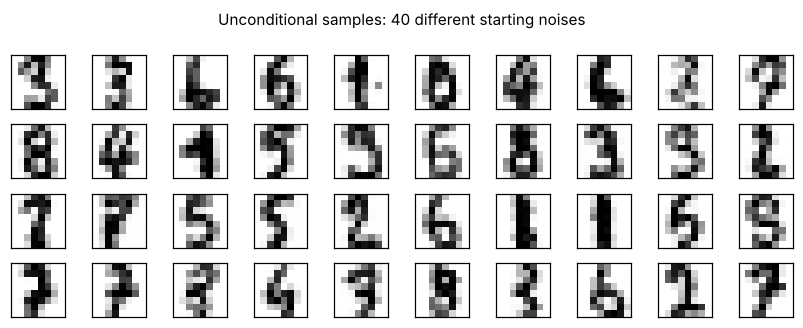

How the judge classifies 100 unconditional samples, by digit 0-9: [ 7  7 11 12  8 10 12  6 16 11]
median distance from a sample to its nearest training image: 2.27
median distance from a training image to its nearest *other* training image: 2.30


In [10]:
uncond = sample_ddpm(noise(100, 1), np.full(100, NULL), seed=1)[0]
show_grid(uncond[:40], 4, 10, "Unconditional samples: 40 different starting noises")
counts = np.bincount(classify(uncond), minlength=10)
print("How the judge classifies 100 unconditional samples, by digit 0-9:", counts)

flat_train = X.reshape(len(X), -1)
nearest = np.sqrt(((uncond.reshape(100, 1, -1) - flat_train[None]) ** 2).sum(-1).min(1))
pairs = np.sqrt(((flat_train[:300, None] - flat_train[None, 300:]) ** 2).sum(-1).min(1))
print(f"median distance from a sample to its nearest training image: {np.median(nearest):.2f}")
print(f"median distance from a training image to its nearest *other* training image: {np.median(pairs):.2f}")

You get a mix of all ten digits, close to the 10% each in the data. Samples are about as far from their nearest
training image as training images are from each other, so the model makes **new** digits rather than copying.

## 7b. The noise is a code: same noise, same image (with DDIM)

With the stochastic DDPM sampler, extra noise is injected at every step, so the starting noise is only part of the
randomness. With deterministic DDIM, the starting noise determines the image completely, like a latent code.

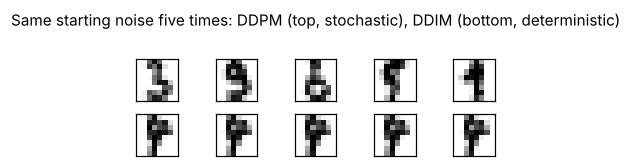

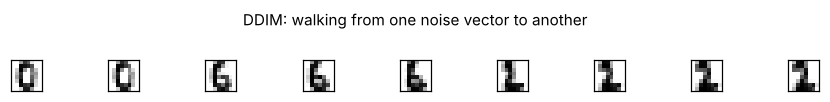

In [11]:
z = noise(1, 42).repeat(5, 0)
ddpm_same_start = sample_ddpm(z, np.full(5, NULL), seed=3)[0]       # same x_T, different noise along the way
ddim_same_start = sample_ddim(z, np.full(5, NULL))                  # same x_T, deterministic
show_grid(np.r_[ddpm_same_start, ddim_same_start], 2, 5,
          "Same starting noise five times: DDPM (top, stochastic), DDIM (bottom, deterministic)")

# Interpolating between two noise vectors (spherical interpolation keeps the norm typical of Gaussian noise).
za, zb = noise(1, 11)[0], noise(1, 12)[0]
omega = np.arccos(np.sum(za * zb) / (np.linalg.norm(za) * np.linalg.norm(zb)))
alphas = np.linspace(0, 1, 9)
zs = np.stack([(np.sin((1 - a) * omega) * za + np.sin(a * omega) * zb) / np.sin(omega) for a in alphas])
show_grid(sample_ddim(zs, np.full(9, NULL)), 1, 9, "DDIM: walking from one noise vector to another", size=0.9)

## 8. Answer, part 2: you choose the content with the label

**Rows: same label. Columns: same starting noise.** Within a column, only the label changes; within a row, only
the noise changes.

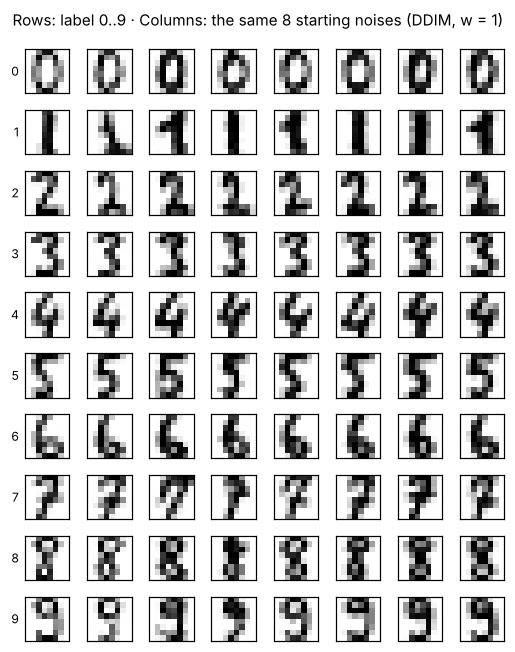

judge agrees with the requested label for 100.0% of these samples


In [12]:
z = noise(8, 5)
xT = np.tile(z, (10, 1, 1, 1))                         # the 8 noises, repeated for each of the 10 labels
labels = np.repeat(np.arange(10), 8)
cond = sample_ddim(xT, labels, w=1.0)
show_grid(cond, 10, 8, "Rows: label 0..9 · Columns: the same 8 starting noises (DDIM, w = 1)",
          row_labels=[str(d) for d in range(10)], size=0.6)
print(f"judge agrees with the requested label for {np.mean(classify(cond) == labels):.1%} of these samples")

Each column is the same noise, yet each row is the requested digit. Look across a column and you can often see the
noise's "style" carried over (slant, thickness, position). **The noise sets the style; the label sets the content.**

### How strongly should the model follow the label? Classifier-free guidance

We measure two things for each guidance weight $w$: how often the sample is the requested digit, and how varied
samples of the same digit are (mean pixel standard deviation across samples).

w = 0.0: requested digit  96.7%   judge's confidence 0.933   distance between two samples of the same digit 4.19   pixels at full black/white 54%


w = 1.0: requested digit 100.0%   judge's confidence 0.993   distance between two samples of the same digit 3.82   pixels at full black/white 55%


w = 3.0: requested digit 100.0%   judge's confidence 0.995   distance between two samples of the same digit 3.85   pixels at full black/white 54%


w = 6.0: requested digit 100.0%   judge's confidence 0.993   distance between two samples of the same digit 4.14   pixels at full black/white 52%


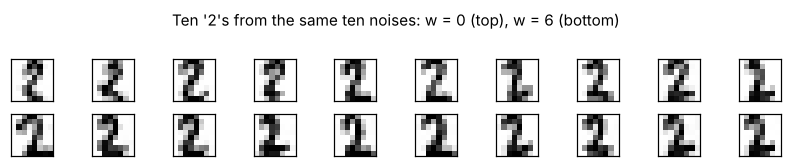

In [13]:
labels = np.repeat(np.arange(10), 30)
for w in [0.0, 1.0, 3.0, 6.0]:
    S = sample_ddim(noise(300, 9), labels, w=w)
    flat = S.reshape(len(S), -1)
    acc = np.mean(classify(S) == labels)
    conf = np.mean(judge.predict_proba(flat)[np.arange(len(S)), labels])
    variety = np.mean([np.sqrt(((flat[labels == d][:, None] - flat[labels == d][None]) ** 2).sum(-1)).mean()
                       for d in range(10)])
    saturated = np.mean(np.abs(flat) > 0.95)
    print(f"w = {w:3.1f}: requested digit {acc:6.1%}   judge's confidence {conf:.3f}   "
          f"distance between two samples of the same digit {variety:.2f}   pixels at full black/white {saturated:.0%}")
show_grid(sample_ddim(noise(10, 9), np.full(10, 2), w=0.0).tolist()
          + sample_ddim(noise(10, 9), np.full(10, 2), w=6.0).tolist(), 2, 10,
          "Ten '2's from the same ten noises: w = 0 (top), w = 6 (bottom)")

Guidance does what it promises for the label: the requested digit goes from about 97% to 100%, and the judge's
confidence from 0.93 to 0.99. In large text-to-image models a high $w$ also visibly reduces variety and
over-saturates colours. On 8×8 digits that side effect is small: variety dips at $w$ = 1–3 and comes back at
$w$ = 6, and saturation doesn't change. The figure shows the trade-off qualitatively: the $w = 6$ row is bolder and
more uniform. In text-to-image models $w$ is the "guidance scale" or "CFG" setting, typically 5–10.

## 9. Answer, part 3: getting a *specific* image (SDEdit)

If you want something close to a particular image you have, don't start from pure noise. Noise **that image** up
to some step $t_0 < T$, then run the reverse process from $t_0$ (Meng et al. 2022, "SDEdit"). Because at $t_0$ some
of the original signal survives (section 2), the result stays close to it. Here we start from training "7"s, noise
them to different depths, and denoise them *without* a label.

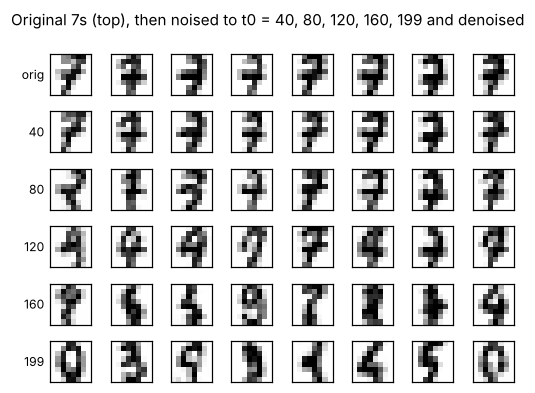

t0 =  40: still a 7:  100%   distance to the original image: 1.30
t0 =  80: still a 7:   90%   distance to the original image: 2.33
t0 = 120: still a 7:   60%   distance to the original image: 3.64
t0 = 160: still a 7:   15%   distance to the original image: 4.99
t0 = 199: still a 7:   10%   distance to the original image: 5.97


In [14]:
sevens = X[Y == 7][:20]
rows, kept = [sevens[:8]], []
for t0 in [40, 80, 120, 160, 199]:
    xt0 = q_sample(sevens, t0, noise(20, t0))
    out = sample_ddim(xt0, np.full(20, NULL), n_steps=max(10, t0 // 4), t_start=t0)
    rows.append(out[:8])
    kept.append((t0, np.mean(classify(out) == 7), np.sqrt(((out - sevens) ** 2).sum((1, 2, 3))).mean()))
show_grid(np.concatenate(rows), 6, 8, "Original 7s (top), then noised to t0 = 40, 80, 120, 160, 199 and denoised",
          row_labels=["orig", "40", "80", "120", "160", "199"], size=0.6)
for t0, frac7, dist in kept:
    print(f"t0 = {t0:3d}: still a 7: {frac7:5.0%}   distance to the original image: {dist:.2f}")

A shallow $t_0$ gives back almost the same 7. Deeper noising keeps less of the original, and by $t_0 = T - 1$ the
output is unrelated to it: a random digit, as in section 7. So the answer to *"how do I get the image I want?"* is:

| You want | You give the model |
| --- | --- |
| any new image like the data | fresh noise $x_T$, no condition |
| a new image **of a kind** (a "3"; "a cat in the snow") | fresh noise **and** a condition (label or text), optionally with guidance |
| the **same** generated image again | the same noise, with a deterministic sampler (DDIM) |
| a variation of **a specific existing** image | that image, partially noised to $t_0$, then denoised (SDEdit; inpainting and image-to-image work the same way) |

Text-to-image systems work exactly like section 8, with two changes: the label lookup table is replaced by a text
encoder (CLIP or T5) whose embeddings enter the U-Net through **cross-attention**, and the diffusion runs in the
latent space of an autoencoder rather than on pixels (Stable Diffusion).

## Things to try

- Set `P_UNCOND = 0` and retrain: guidance stops working, because the model never learned $\varepsilon_\theta(x_t, t, \varnothing)$.
- Remove the skip connection (`concat skip`) and compare samples: detail has to pass through the 4×4 bottleneck.
- Replace the cosine schedule by DDPM's linear one (`BETAS = np.linspace(1e-4, 0.02 * 1000 / T, T)`) and look at section 2.
- Change `n_steps` in `sample_ddim` to 10 or 5: how few steps still give digits?